# The synthesizer and the Didge Archive: does the simulation sound like the real instruments?

The [Didge Archive](https://github.com/Didgitaldoo/didge-archive) contains, for nine didgeridoos, the
measured bore and recordings of the same instrument. This notebook compares the DidgeLab synthesizer
(`didgelab.synth`) with these recordings:

1. **Introduction**: what is compared and why
2. **Maths**: pitch tracking, cents, toot clusters, harmonic spectra and the error measures
3. **Code examples**: drone pitch, toots, the timbre of the drone, and the stored full evaluation

The full evaluation is `scripts/synth/evaluate_archive.py`; its results are in
`doc/results/synth/archive_eval.json` and described in [synthesizer.md](../synthesizer.md), section 7.

## 1. Introduction

The synthesizer computes the sound of a didgeridoo **from its shape only**. Nobody tuned it on a recording of
that instrument. So we can test it: take a didgeridoo of the archive, simulate it, and compare with what the
real instrument sounds like when it is played.

For each instrument the archive has

* the **geometry**: diameter along the bore, measured from the 3-D model it was printed from,
* a **neutral drone**: a plain drone, relaxed mouth, no rhythm,
* **hand slaps** on the mouthpiece (for some instruments),
* a **song** or a longer performance.

We check three things a player hears.

**The drone pitch.** The drone is the lowest resonance of the bore. DidgeLab computes it. Does the real
instrument drone at the same pitch? We measure the pitch of the neutral recording and compare. Differences are
given in **cents**: 100 cents are one semitone. A player holds a drone only to within roughly 10–20 cents.

**The toots.** A toot is played on a higher resonance. In the songs we look for long, stable notes above the
drone and check whether they sit on a resonance that DidgeLab predicts. Care is needed: a strong overtone of
the drone could be mistaken for a toot. So a note only counts as a toot if it is closer to a resonance than to
an overtone of the drone.

**The colour (timbre) of the drone.** A drone is made of a fundamental and many overtones (harmonics) at 2, 3,
4, ... times its frequency. How loud each harmonic is depends on the bore: a harmonic that falls on a
resonance is strong, one that falls between two resonances is weak. This pattern is like a **fingerprint** of
the instrument. We measure it in the neutral recording and compare it with the synthesized drone. If the
model is good, each recording should look most like the model of *its own* instrument.

One correction of the archive index is needed: the entry "Tamaki2" points to the geometry of the Open
Didgeridoo. But the archive also contains `tamaki2.json`, and with it the simulated drone matches the
recording, while the Open Didgeridoo geometry is far off. `didgelab.synth.archive` therefore uses
`tamaki2.json` for Tamaki2 (`GEOMETRY_OVERRIDES`). Section 3.2 shows the difference.

## 2. Maths

### 2.1 Cents

The distance between two frequencies $f$ and $f_{\text{ref}}$ in cents is

$$
c = 1200 \log_2 \frac{f}{f_{\text{ref}}} .
$$

100 cents are one equal-tempered semitone, 1200 cents an octave. Errors below are recorded minus simulated.

### 2.2 Pitch tracking (`track_f0`)

The recording is resampled to 48 kHz and analysed with a short-time Fourier transform (hop 10 ms, window 4096,
FFT size 8192); $L_t(f)$ is the log magnitude (dB) of frame $t$. For a candidate frequency $f$ (5-cent grid
between $f_{\min}$ and $f_{\max}$) the **harmonic-contrast score** compares the level at the first 12
harmonics with the level half-way between them:

$$
s_t(f) = \frac{1}{12}\sum_{n=1}^{12} L_t(nf) \;-\; \frac{1}{12}\sum_{n=1}^{12} L_t\!\left(\left(n - \tfrac12\right) f\right).
$$

The best candidate $\hat f_t = \arg\max_f s_t(f)$ is then checked for octave errors: if $\hat f_t / k$
($k = 4, 3, 2$) scores within a margin $m$ of the maximum, the lower candidate is preferred ($m = 8$ dB by
default, $m = 2$ dB for the toot search). The frequency is refined by a parabola through the scores of the
neighbouring candidates. A frame is voiced if $s_t > 6$ dB and its level is within 45 dB of the loudest frame.
The **drone of a recording** is the median of $\hat f_t$ over the voiced frames.

The **simulated drone** $f_1$ is the first impedance peak of the bore computed by DidgeLab; $f_k$ is the
$k$-th peak.

### 2.3 Toot clusters

In a song, frames with a clear pitch ($s_t > 15$ dB, search range $0.8 f_1 \dots 1.1 f_6$) are collected as
cents above the drone resonance, $c_t = 1200\log_2(\hat f_t / f_1)$, in a histogram with 25-cent bins from 150
to 3300 cents. A bin with at least 8 frames that is the largest within $\pm 3$ bins is a **cluster**; its
frequency $f_{\text{rec}}$ is the median of the frames within 60 cents. With the nearest resonance $f_k$
($k \ge 2$) and the nearest harmonic $h f_1$, $h = \mathrm{round}(f_{\text{rec}}/f_1)$, the cluster is a toot if

$$
\left| 1200\log_2\frac{f_{\text{rec}}}{f_k} \right| < \left| 1200\log_2\frac{f_{\text{rec}}}{h f_1} \right| .
$$

### 2.4 Harmonic spectrum of a recording

For every voiced frame the level of harmonic $n$ is the peak of $L_t$ within $\pm 3\,\% / \sqrt{n}$ of
$n \hat f_t$: $H_{t,n}$ (dB). The **long-term harmonic spectrum** is the power average over frames,

$$
\bar L_n = 10 \log_{10} \left( \frac{1}{T} \sum_t 10^{H_{t,n}/10} \right).
$$

### 2.5 Harmonic spectrum of the model

The synthesizer radiates the harmonics $P_n = S_n \, G(n f_0)$, where $S_n$ are the harmonics of the beating-lip
source flow (open quotient 0.45, skew 0.85) and $G$ is the transfer from source flow to radiated pressure,

$$
G(f) = \frac{j f}{100}\, H(f)\, \frac{Z_s}{Z_s + Z_{\text{in}}(f) + Z_{\text{vt}}(f)} \cdot 10^{\,\tau \log_2(f/1000)/20},
$$

with the pressure transfer $H$ and input impedance $Z_{\text{in}}$ of the bore (DidgeLab transmission-line
model), the vocal-tract impedance $Z_{\text{vt}}$ of the neutral mouth, the lip source impedance
$Z_s = 0.1$ MPa s m⁻³ and a directivity tilt $\tau = +1$ dB/octave. The model level is
$M_n = 20\log_{10}|P_n|$.

### 2.6 Harmonic fingerprint

For recording $i$ and model $j$, both are evaluated at the recorded drone $f_0^{(i)}$ and normalised to
their first harmonic. The difference of harmonics $n = 2 \dots 10$,

$$
r_n = \left(\bar L^{(i)}_n - \bar L^{(i)}_1\right) - \left(M^{(j)}_n - M^{(j)}_1\right),
$$

is fitted with an offset and a spectral tilt, $r_n \approx a + b \log_2 n$ (least squares; this absorbs the
microphone and the room), and the distance is the rms of the residual,

$$
D_{ij} = \sqrt{\frac{1}{9}\sum_{n=2}^{10} \left(r_n - a - b\log_2 n\right)^2 } .
$$

A recording is **classified correctly** if the closest model $\arg\min_j D_{ij}$ has the same geometry. The
**rank** of the correct model is the number of models that are closer than it (0 = best).

### 2.7 Spectral envelope in third-octave bands

The power of harmonics 1–80 is summed in one-third-octave bands $b$ ($63\,\text{Hz} \cdot 2^{b/3}$), giving
$B^{\text{rec}}_b$ and $B^{\text{model}}_b$ (dB). Only a common gain is removed:

$$
e = \sqrt{ \overline{ \left(d_b - \bar d\right)^2 } }, \qquad d_b = B^{\text{rec}}_b - B^{\text{model}}_b .
$$

## 3. Code examples

In [1]:
import sys, os, io, json, warnings
sys.path.insert(0, "../../src")   # use the didgelab of this repository

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Audio, Image, display
from scipy.signal import resample_poly

from didgelab.synth import archive, Bore, ModelParams, Synthesizer, VOWELS
from didgelab.synth.analysis import load_audio, stft, track_f0, harmonic_amplitudes, ltas_harmonics
from didgelab.synth.model import harmonic_db
from didgelab.synth.techniques import score_controls

plt.rcParams["figure.dpi"] = 72
FS = 48000
RESULTS = "../results/synth"
root = archive.locate(os.environ.get("DIDGE_ARCHIVE"))   # set DIDGE_ARCHIVE to avoid a download

def show_jpeg(fig, quality=80):
    """Show a figure as JPEG (dense spectra are much smaller as JPEG than as PNG)."""
    buf = io.BytesIO()
    fig.savefig(buf, format="jpeg", pil_kwargs={"quality": quality})
    plt.close(fig)
    display(Image(data=buf.getvalue(), format="jpeg"))

def cents(a, b):
    return 1200 * np.log2(a / b)

insts = archive.load(root)
bores = {i.name: Bore(i.geometry) for i in insts}
pd.DataFrame([{"instrument": i.name, "shape": i.shape, "geometry": i.geometry_file,
               "recordings": ", ".join(sorted(i.samples)),
               "resonances / Hz": ", ".join(f"{r.freq:.0f}" for r in bores[i.name].resonances[:5])}
              for i in insts]).set_index("instrument")

,shape,geometry,recordings,resonances / Hz
instrument,,,,
Malveira,straight,geometries/malveira.json,"hand-closed, hand-open, neutral-sound, song","93, 185, 354, 462, 544"
Arusha,saxodidge,geometries/arusha.json,"hand-closed, hand-open, neutral-sound, song","74, 147, 223, 350, 448"
Nazare,straight,geometries/nazare.json,"hand-closed, hand-open, neutral-sound, song","74, 184, 282, 417, 513"
Kizimkazi,straight,geometries/kizimkazi.json,"hand-closed, hand-open, neutral-sound, song","74, 223, 372, 541, 686"
Open Didgeridoo,saxodidge,geometries/opendidgeridoo.json,"hand-closed, hand-open, neutral-sound, song","74, 187, 297, 403, 516"
Open Didgeridoo Straight,straight,geometries/opendidgeridoo.json,"neutral-sound, song","74, 187, 297, 403, 516"
Tamaki1,straight,geometries/tamaki1.json,"neutral-sound, song","77, 216, 301, 460, 529"
Tamaki2,straight,geometries/tamaki2.json,"neutral-sound, song","72, 201, 310, 436, 533"
Matema,straight,geometries/matema.json,"neutral-sound, song","74, 146, 250, 331, 447"


### 3.1 Drone pitch

For every instrument we track the pitch of the neutral recording and compare its median with the first
DidgeLab resonance.

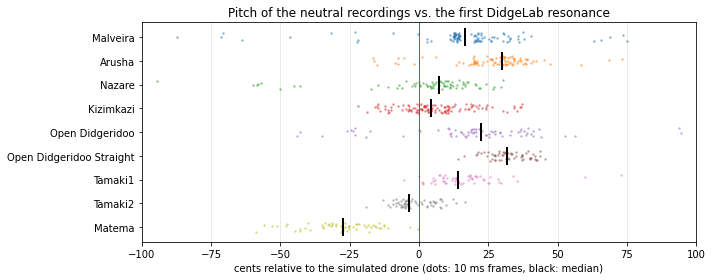

mean absolute error 17 cents, mean error +10.6 cents


,simulated / Hz,recorded / Hz,error / cents
instrument,,,
Malveira,93.1,94.0,16.8
Arusha,74.0,75.3,30.0
Nazare,74.1,74.5,7.1
Kizimkazi,74.3,74.5,4.5
Open Didgeridoo,73.8,74.8,22.3
Open Didgeridoo Straight,73.8,75.2,31.8
Tamaki1,76.6,77.3,14.1
Tamaki2,72.3,72.2,-3.5
Matema,74.0,72.9,-27.2


In [2]:
neutral, rows = {}, []
fig, ax = plt.subplots(figsize=(10, 4))
for k, ins in enumerate(insts):
    x, fs = load_audio(ins.samples["neutral-sound"], FS)
    spec = stft(x, fs)
    tr = track_f0(x, fs, spec=spec)
    f0 = float(np.nanmedian(tr.f0))
    H = harmonic_amplitudes(spec, tr.f0, n_harm=80, fmax=6000)
    with warnings.catch_warnings():          # harmonics above 6 kHz are NaN in every frame
        warnings.simplefilter("ignore", RuntimeWarning)
        neutral[ins.name] = (f0, ltas_harmonics(H), x)
    sim = bores[ins.name].drone
    rows.append({"instrument": ins.name, "simulated / Hz": sim, "recorded / Hz": f0,
                 "error / cents": cents(f0, sim)})
    c = cents(tr.f0[np.isfinite(tr.f0)], sim)
    ax.plot(c, np.full(len(c), k) + np.random.default_rng(k).uniform(-0.2, 0.2, len(c)), ".", ms=3, alpha=0.4)
    ax.plot(cents(f0, sim), k, "k|", ms=18, mew=2)
ax.axvline(0, color="#1f77b4", lw=1)
ax.set_yticks(range(len(insts))); ax.set_yticklabels([i.name for i in insts]); ax.invert_yaxis()
ax.set_xlim(-100, 100); ax.grid(alpha=0.3, axis="x")
ax.set_xlabel("cents relative to the simulated drone (dots: 10 ms frames, black: median)")
ax.set_title("Pitch of the neutral recordings vs. the first DidgeLab resonance")
plt.tight_layout(); plt.show()

drone = pd.DataFrame(rows).set_index("instrument")
e = drone["error / cents"]
print(f"mean absolute error {e.abs().mean():.0f} cents, mean error {e.mean():+.1f} cents")
drone.round(1)

The simulated drones are within a few tens of cents of the recordings, on average about 18 cents; the players
hold the drone on average about 11 cents above the first resonance. That is about the precision with which a
player holds a drone. Only Matema is clearly flat (about −27 cents): it is played lower than DidgeLab predicts.

### 3.2 Why Tamaki2 uses `tamaki2.json`

The archive index assigns the Open Didgeridoo geometry to Tamaki2. Compare both geometries with the Tamaki2
recording:

In [3]:
print("GEOMETRY_OVERRIDES:", archive.GEOMETRY_OVERRIDES)
index = json.load(open(root / "didge-archive.json"))
print("index entry of Tamaki2:", [d["geometry"] for d in index if d["name"] == "Tamaki2"][0])
f_rec = neutral["Tamaki2"][0]
for gfile in ["geometries/opendidgeridoo.json", "geometries/tamaki2.json"]:
    b = Bore(json.load(open(root / gfile)))
    print(f"{gfile:34s} simulated drone {b.drone:6.1f} Hz, recorded {f_rec:.1f} Hz: {cents(f_rec, b.drone):+5.0f} cents")

GEOMETRY_OVERRIDES: {'Tamaki2': 'geometries/tamaki2.json'}
index entry of Tamaki2: geometries/opendidgeridoo.json
geometries/opendidgeridoo.json     simulated drone   73.8 Hz, recorded 72.2 Hz:   -38 cents
geometries/tamaki2.json            simulated drone   72.3 Hz, recorded 72.2 Hz:    -4 cents


With the geometry from the index the drone is almost half a semitone off; with `tamaki2.json` it is as close
as for the other instruments. So the index most likely points to the wrong file.

### 3.3 Toots in the songs

We search the songs for stable pitches above the drone (section 2.3). Each cluster is compared with the nearest
DidgeLab resonance and the nearest harmonic of the drone. A cluster within 50 cents of a harmonic is
ambiguous and not counted as a toot.

In [4]:
clusters, hist = [], {}
for ins in insts:
    b = bores[ins.name]
    res = np.array([r.freq for r in b.resonances[:6]])
    x, fs = load_audio(ins.samples["song"], FS)
    tr = track_f0(x, fs, fmin=0.8 * res[0], fmax=1.1 * res[-1], sub_margin=2.0)
    ok = np.isfinite(tr.f0) & (tr.score > 15)
    c = cents(tr.f0[ok], res[0])
    h, edges = np.histogram(c, bins=np.arange(150, 3300, 25))
    hist[ins.name] = (h, edges, res)
    for i in range(len(h)):
        if h[i] >= 8 and h[i] == h[max(0, i - 3):i + 4].max():
            f_rec = float(np.median(tr.f0[ok][np.abs(c - (edges[i] + 12.5)) < 60]))
            k = int(np.argmin(np.abs(cents(f_rec, res[1:])))) + 1
            harm = round(f_rec / res[0])
            d_res, d_harm = cents(f_rec, res[k]), cents(f_rec, harm * res[0])
            clusters.append({"instrument": ins.name, "recorded / Hz": f_rec, "frames": int(h[i]),
                             "resonance": k + 1, "DidgeLab / Hz": res[k], "error / cents": d_res,
                             "nearest harmonic": harm, "cents to harmonic": d_harm,
                             "toot?": abs(d_res) < abs(d_harm) and abs(d_harm) > 50})
pd.DataFrame(clusters).set_index("instrument").round(1)

,recorded / Hz,frames,resonance,DidgeLab / Hz,error / cents,nearest harmonic,cents to harmonic,toot?
instrument,,,,,,,,
Arusha,227.3,17,3,222.7,35.7,3,39.6,False
Nazare,83.5,11,2,183.5,-1363.2,1,205.6,False
Open Didgeridoo,225.0,9,2,186.6,324.2,3,27.7,False
Open Didgeridoo Straight,226.6,20,2,186.6,336.6,3,40.1,False
Tamaki1,212.9,95,2,216.2,-26.9,3,-133.6,True
Tamaki1,231.7,10,2,216.2,120.1,3,13.3,False
Tamaki2,196.0,50,2,200.6,-40.0,3,-176.5,True
Matema,145.5,135,2,145.9,-4.6,2,-31.1,False


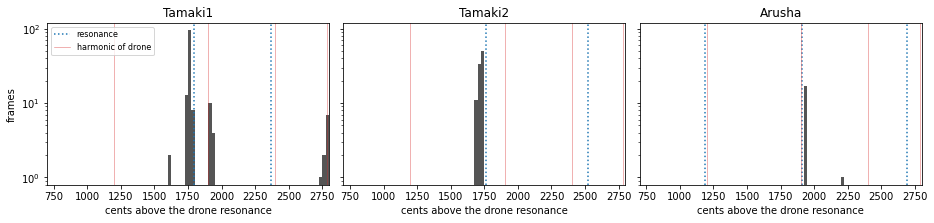

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, name in zip(axs, ["Tamaki1", "Tamaki2", "Arusha"]):
    h, edges, res = hist[name]
    ax.bar(edges[:-1] + 12.5, h, width=25, color="#555")
    for k, r in enumerate(res[1:5], 2):
        ax.axvline(cents(r, res[0]), color="#1f77b4", ls=":", label="resonance" if k == 2 else None)
    for n in range(2, 9):
        ax.axvline(1200 * np.log2(n), color="#d62728", lw=0.6, alpha=0.6, label="harmonic of drone" if n == 2 else None)
    ax.set_xlim(700, 2800); ax.set_yscale("log"); ax.set_title(name)
    ax.set_xlabel("cents above the drone resonance")
axs[0].set_ylabel("frames"); axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

In Tamaki1 and Tamaki2 the main cluster lies clearly *below* the 3rd harmonic of the drone and close to the
2nd DidgeLab resonance: these are toots. They are played 27–40 cents below the resonance. In Arusha the 3rd
resonance coincides with the 3rd harmonic of the drone; the cluster is within 40 cents of the harmonic, so it
is ambiguous and not counted as a toot. The Open Didgeridoo clusters are the 3rd harmonic as well (far from
any resonance). Matema has a cluster right on its 2nd resonance, but it is also within 31 cents of the 2nd
harmonic of its (flat) drone, so it is ambiguous too.

The drone is played on the resonance, the toots 27–40 cents below it. A plausible reason
([synthesizer.md](../synthesizer.md) §7.2): the lips cannot follow the higher, narrower resonance exactly.
The synthesizer therefore plays toots 34 cents below the resonance (`ModelParams.toot_cents`).

### 3.4 The timbre of the drone: spectra

Now we synthesize the neutral drone of every instrument (relaxed mouth `uh`, two beats at 60 BPM) and compare
its spectrum with the neutral recording, as `evaluate_archive.py` does for figure 5 of the article.

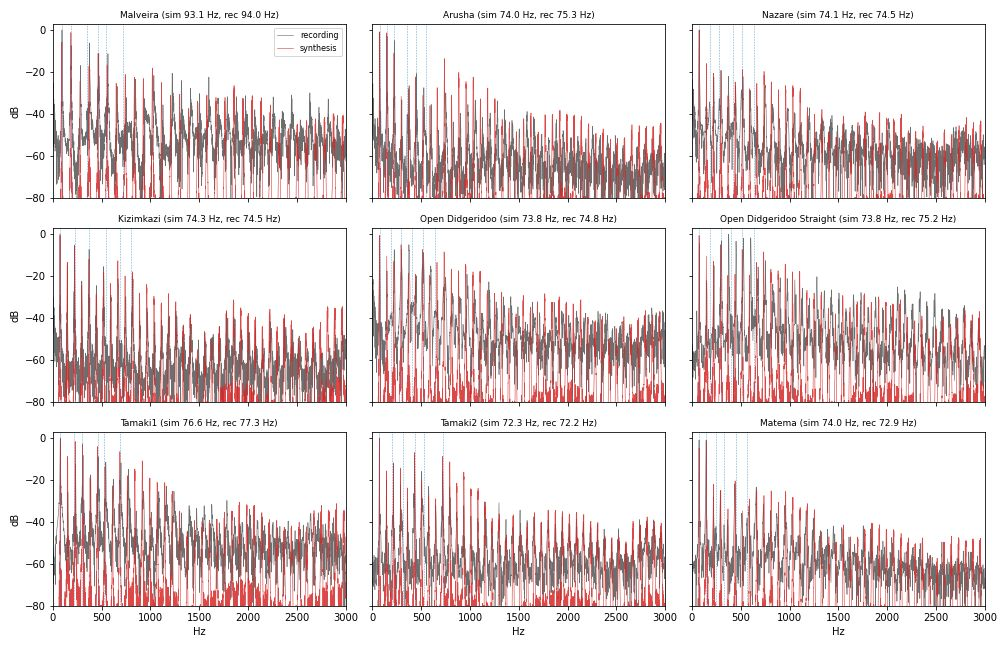

In [6]:
params = ModelParams()
synth = {}
for ins in insts:
    c = score_controls(bores[ins.name], "tempo = 60\nuh:2", params)
    synth[ins.name] = Synthesizer(bores[ins.name], params, seed=0).render(c, reverb=0.15)

def spectrum(sig):
    N = len(sig)
    X = np.abs(np.fft.rfft(sig * np.hanning(N), 2 * N))
    f = np.fft.rfftfreq(2 * N, 1 / FS)
    S = 20 * np.log10(X + 1e-12)
    m = f < 3000
    return f[m][::2], (S[m] - S[m].max())[::2]

fig, axs = plt.subplots(3, 3, figsize=(14, 9), sharex=True, sharey=True)
for ax, ins in zip(axs.ravel(), insts):
    f0, L, x = neutral[ins.name]
    y = synth[ins.name][int(0.3 * FS):int(1.8 * FS)]
    for sig, lab, col in [(x, "recording", "#555"), (y, "synthesis", "#d62728")]:
        ax.plot(*spectrum(sig), lw=0.6, color=col, label=lab, alpha=0.85)
    for r in bores[ins.name].resonances[:6]:
        ax.axvline(r.freq, color="#1f77b4", lw=0.6, ls=":")
    ax.set_title(f"{ins.name} (sim {bores[ins.name].drone:.1f} Hz, rec {f0:.1f} Hz)", fontsize=9)
    ax.set_ylim(-80, 3); ax.set_xlim(0, 3000)
axs[0, 0].legend(fontsize=8)
for ax in axs[-1]:
    ax.set_xlabel("Hz")
for ax in axs[:, 0]:
    ax.set_ylabel("dB")
plt.tight_layout(); show_jpeg(fig)

Grey is the recording, red the synthesis, dotted lines the DidgeLab resonances. Both have the same overall
shape: strong harmonics near the resonances, weak ones in between, and a falling envelope with a bump around
1–2 kHz from the mouth.

Listen to Kizimkazi: first the recording, then the synthesized neutral drone (resampled to 16 kHz):

In [7]:
x = neutral["Kizimkazi"][2][:int(1.5 * FS)]
y = synth["Kizimkazi"][int(0.3 * FS):int(1.8 * FS)]
clip = np.concatenate([x / np.abs(x).max(), np.zeros(int(0.4 * FS)), y / np.abs(y).max()]) * 0.8
Audio(resample_poly(clip, 1, 3), rate=16000, normalize=False)

### 3.5 Harmonic fingerprint

The relative levels of the first ten harmonics (section 2.6). Below: the measured pattern of three recordings
and the model of the same instrument.

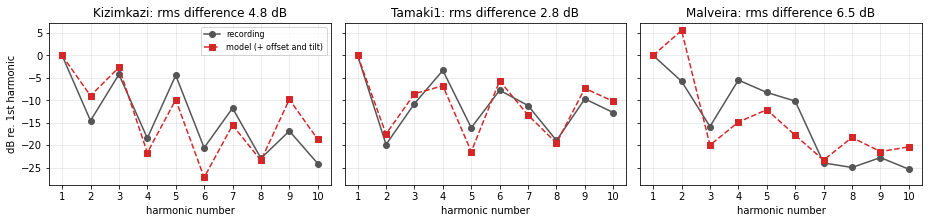

In [8]:
NL = 10
n = np.arange(1, NL + 1)
names = [i.name for i in insts]

def pattern(bname, f0):
    M = harmonic_db(bores[bname], f0, VOWELS["neutral"], params, NL)
    return M - M[0]

def pair_dist(L, M):
    r = (L[1:NL] - L[0]) - M[1:]
    X = np.stack([np.log2(n[1:]), np.ones(NL - 1)], 1)
    coef, *_ = np.linalg.lstsq(X, r, rcond=None)
    return float(np.sqrt(np.mean((r - X @ coef) ** 2))), coef

fig, axs = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, name in zip(axs, ["Kizimkazi", "Tamaki1", "Malveira"]):
    f0, L, _ = neutral[name]
    M = pattern(name, f0)
    d, (b, a) = pair_dist(L, M)
    ax.plot(n, L[:NL] - L[0], "o-", color="#555", label="recording")
    ax.plot(n, M + np.r_[0, a + b * np.log2(n[1:])], "s--", color="#d62728", label="model (+ offset and tilt)")
    ax.set_title(f"{name}: rms difference {d:.1f} dB"); ax.set_xlabel("harmonic number"); ax.set_xticks(n)
    ax.grid(alpha=0.3)
axs[0].set_ylabel("dB re. 1st harmonic"); axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

Kizimkazi, whose resonances lie at about 1, 3, 5 and 7.3 times the drone, has strong odd harmonics, and the
model reproduces that. Tamaki1 matches well too. Malveira is one of the recordings where the pattern is not
reproduced well (its 2nd harmonic is too strong in the model). Now every recording against every model:

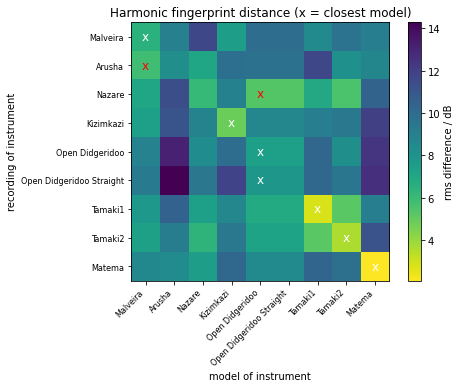

correct instrument: 7 / 9, mean rank of the correct model 0.7, chance 0.125 (Open Didgeridoo and Open Didgeridoo Straight share one geometry and count as one class)


In [9]:
D = np.array([[pair_dist(neutral[a][1], pattern(b, neutral[a][0]))[0] for b in names] for a in names])
same = {i: [j for j in range(len(names)) if insts[j].geometry_file == insts[i].geometry_file] for i in range(len(names))}
correct = [int(np.argmin(D[i])) in same[i] for i in range(len(names))]
rank = [int(np.sum(D[i] < min(D[i, j] for j in same[i]))) for i in range(len(names))]

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(D, cmap="viridis_r")
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8)
for i in range(len(names)):
    j = int(np.argmin(D[i]))
    ax.text(j, i, "x", ha="center", va="center", color="w" if correct[i] else "r", fontsize=12)
ax.set_xlabel("model of instrument"); ax.set_ylabel("recording of instrument")
plt.colorbar(im, label="rms difference / dB")
ax.set_title("Harmonic fingerprint distance (x = closest model)")
plt.tight_layout(); plt.show()
print(f"correct instrument: {sum(correct)} / {len(names)}, mean rank of the correct model {np.mean(rank):.1f}, "
      f"chance {1 / len(set(i.geometry_file for i in insts)):.3f} "
      "(Open Didgeridoo and Open Didgeridoo Straight share one geometry and count as one class)")

### 3.6 Spectral envelope in third-octave bands

Finally the band levels of section 2.7, with the default parameters of the synthesizer (`ModelParams()`), for
each instrument:

In [10]:
NH = 80
nn = np.arange(1, NH + 1)
band_edges = 63 * 2 ** (np.arange(0, 20) / 3)

def bands(f, Ldb):
    P = 10 ** (Ldb / 10)
    return np.array([10 * np.log10(P[(f >= lo) & (f < hi)].sum()) if np.any((f >= lo) & (f < hi)) else np.nan
                     for lo, hi in zip(band_edges[:-1], band_edges[1:])])

def band_err(rb, mb):
    ok = np.isfinite(rb) & np.isfinite(mb)
    d = rb[ok] - mb[ok]
    return float(np.sqrt(np.mean((d - d.mean()) ** 2)))

be = {}
for nm in names:
    f0, L, _ = neutral[nm]
    be[nm] = {"model (defaults)": band_err(bands(nn * f0, L), bands(nn * f0, harmonic_db(bores[nm], f0, VOWELS["neutral"], params, NH))),
              "generic 1/n spectrum": band_err(bands(nn * f0, L), bands(nn * f0, 20 * np.log10(1 / nn)))}
be = pd.DataFrame(be).T
print(f"mean rms band error: model {be.iloc[:, 0].mean():.1f} dB, generic 1/n {be.iloc[:, 1].mean():.1f} dB")
be.round(1).T

mean rms band error: model 5.4 dB, generic 1/n 6.1 dB


,Malveira,Arusha,Nazare,Kizimkazi,Open Didgeridoo,Open Didgeridoo Straight,Tamaki1,Tamaki2,Matema
model (defaults),5.8,5.9,6.2,4.7,5.5,7.6,4.5,5.1,3.6
generic 1/n spectrum,4.0,6.5,5.0,6.0,4.9,8.8,6.4,5.5,7.7


On average the model is a little closer to the recordings than a generic $1/n$ harmonic spectrum, but not
for every instrument (for Malveira the generic spectrum fits better). The band levels of a plain drone are a
weak test; the fingerprint above, which looks at single harmonics, separates the instruments much better.

### 3.7 The stored full evaluation

`scripts/synth/evaluate_archive.py` runs these analyses (and the hand slaps) and stores them in
`archive_eval.json`. Drone pitch and toots:

In [11]:
ae = json.load(open(f"{RESULTS}/archive_eval.json"))
d = pd.DataFrame(ae["drone"]["rows"]).set_index("instrument")
d["this notebook / cents"] = drone["error / cents"]
print(f"drone: mean absolute error {ae['drone']['mean_abs_cents']:.1f} cents, mean {ae['drone']['mean_cents']:+.1f} cents")
d.round(1)

drone: mean absolute error 17.5 cents, mean +10.6 cents


,sim_drone_hz,rec_drone_hz,error_cents,this notebook / cents
instrument,,,,
Malveira,93.1,94.0,16.8,16.8
Arusha,74.0,75.3,30.0,30.0
Nazare,74.1,74.5,7.1,7.1
Kizimkazi,74.3,74.5,4.5,4.5
Open Didgeridoo,73.8,74.8,22.3,22.3
Open Didgeridoo Straight,73.8,75.2,31.8,31.8
Tamaki1,76.6,77.3,14.1,14.1
Tamaki2,72.3,72.2,-3.5,-3.5
Matema,74.0,72.9,-27.2,-27.2


In [12]:
print(f"toot clusters: {ae['toots']['n_toot_clusters']}, mean error {ae['toots']['mean_cents']:+.0f} cents")
print("(in the stored file 'resonance' counts from 0: 1 = 2nd resonance)")
pd.DataFrame(ae["toots"]["clusters"]).set_index("instrument").round(1)

toot clusters: 2, mean error -33 cents
(in the stored file 'resonance' counts from 0: 1 = 2nd resonance)


,rec_hz,frames,resonance,sim_hz,error_cents,nearest_harmonic,harmonic_cents,is_toot
instrument,,,,,,,,
Arusha,227.3,17,2,222.7,35.7,3,39.6,False
Nazare,83.5,11,1,183.5,-1363.2,1,205.6,False
Open Didgeridoo,225.0,9,1,186.6,324.2,3,27.7,False
Open Didgeridoo Straight,226.6,20,1,186.6,336.6,3,40.1,False
Tamaki1,212.9,95,1,216.2,-26.9,3,-133.6,True
Tamaki1,231.7,10,1,216.2,120.1,3,13.3,False
Tamaki2,196.0,50,1,200.6,-40.0,3,-176.5,True
Matema,145.5,135,1,145.9,-4.6,2,-31.1,False


Hand slaps, harmonic fingerprint and band levels:

In [13]:
slaps = pd.DataFrame({k.replace("slap_", ""): ae[k] for k in ["slap_hand-closed", "slap_hand-open"]}).T
slaps.index = ["hand closed vs max |Z_in|", "hand open vs min |Z_in|"]
display(slaps.round(2))

fp = ae["fingerprint"]
display(pd.DataFrame({"this synthesizer": fp["model"], "Didge2Wav (|Z|^1.2 * Hindle)": fp["didge2wav"]}).T
        .rename(columns={"accuracy": "correct instrument", "mean_rank": "mean rank of correct",
                         "diag_rms_db": "rms difference / dB"}).round(2))
print(f"chance level: {fp['chance']:.3f}")

lt = ae["ltas_third_octave"]
pd.Series({"this synthesizer, leave-one-out": lt["model_leave_one_out_db"],
           "this synthesizer, final defaults (ModelParams)": lt["model_default_db"],
           "generic 1/n harmonic spectrum": lt["generic_1_over_n_db"],
           "Didge2Wav": lt["didge2wav_db"]}, name="rms band error / dB").round(1).to_frame()

,n,median_abs_cents,within_50_cents
hand closed vs max |Z_in|,20.0,31.16,0.75
hand open vs min |Z_in|,20.0,24.69,0.95


,correct instrument,mean rank of correct,rms difference / dB
this synthesizer,0.78,0.67,5.48
Didge2Wav (|Z|^1.2 * Hindle),0.11,1.78,11.91


chance level: 0.125


,rms band error / dB
"this synthesizer, leave-one-out",5.1
"this synthesizer, final defaults (ModelParams)",5.4
generic 1/n harmonic spectrum,6.1
Didge2Wav,26.7


What the stored numbers mean:

* **Drone**: mean absolute error about 18 cents, mean error about +11 cents. DidgeLab predicts the drone within
  the precision with which a player holds it; the model therefore plays the drone exactly on the impedance peak.
* **Toots**: Tamaki1 and Tamaki2 have toots on the 2nd resonance, 27–40 cents below it. The other clusters
  are harmonics of the drone (Matema is ambiguous).
* **Hand slaps**: with the hand closing the mouthpiece the spectral peaks match the impedance maxima (median
  31 cents), with the hand lifted away the impedance minima (median 25 cents). Slaps are short and noisy, so
  these are upper bounds of the model error, but they confirm the open/closed assignment.
* **Fingerprint**: this synthesizer finds the right instrument for 7 of 9 recordings (chance 12.5 %), the older
  Didge2Wav model ($|Z|^{1.2}$ with a Hindle source) for 1 of 9. The rms difference of the right pairs is
  about 5.5 dB instead of 11.9 dB.
* **Band levels**: about 5 dB rms with leave-one-instrument-out fitting of the global parameters (open
  quotient, skew, $Z_s$), better than a generic $1/n$ spectrum (6.1 dB) and far better than Didge2Wav
  (26.7 dB). The final defaults of `ModelParams` give 5.5 dB, the same as section 3.6 (the lips are set by ear,
  [synthesizer.md](../synthesizer.md) §7.5).